In [1]:
import scanpy as sc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os
sc.settings.figdir="../results/figures"
adata=sc.read_h5ad("../data/processed/pbmc3k_normalized_hvg.h5ad")

In [2]:
sc.tl.pca(adata,svd_solver="arpack",n_comps=50)

这一步为主成分分析，tl表示tool，与pp（preprocessing）相对。  
选取方法为arpack，选取50个主成分

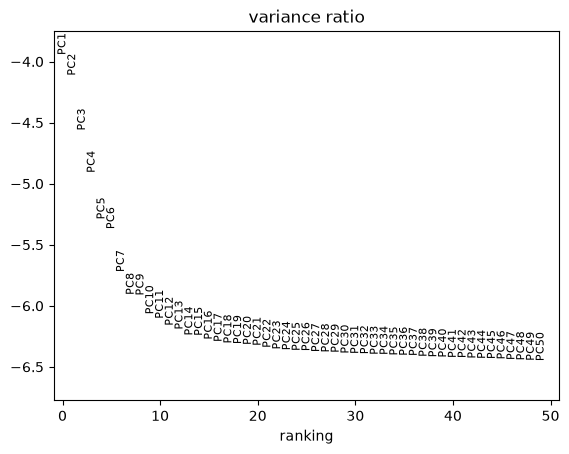

In [3]:
sc.pl.pca_variance_ratio(adata,n_pcs=50,log=True,show=False)
plt.savefig("../results/figures/03_pca_variance_ratio.png",dpi=300,bbox_inches="tight")
plt.show()

PCA方差贡献图。  
主成分选取50个，用对数刻度展示，可以更清晰的看出肘部。  
相当于Seurat的Elbowplot碎石图

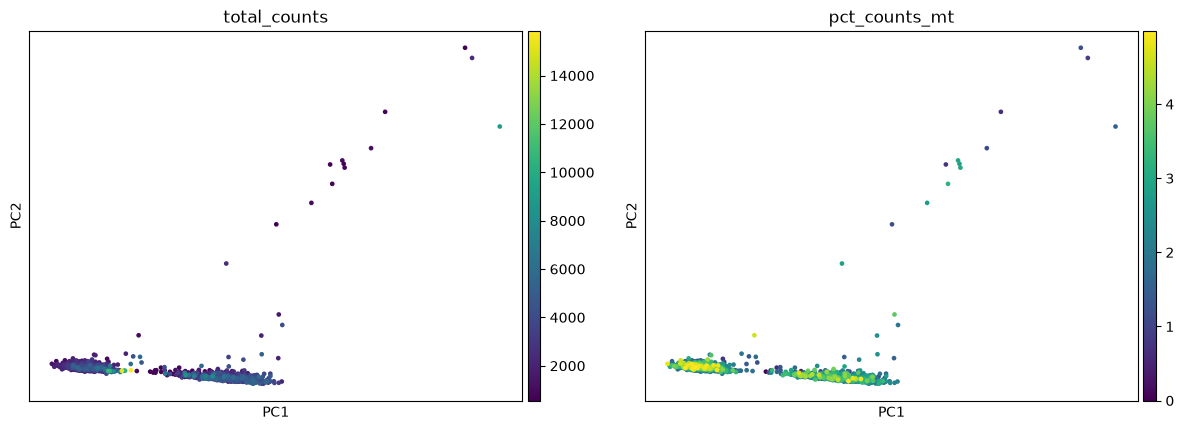

In [4]:
sc.pl.pca(adata,color=["total_counts","pct_counts_mt"],ncols=2,show=False)
plt.savefig("../results/figures/03_pca_qc_check.png",dpi=300,bbox_inches="tight")
plt.show()

在PCA坐标下绘制细胞散点图。  
第一张图用测序深度上色，第二张图用线粒体基因占比上色。
两张图中颜色都没有梯度改变，说明PCA没有被测序深度和线粒体基因占比主导

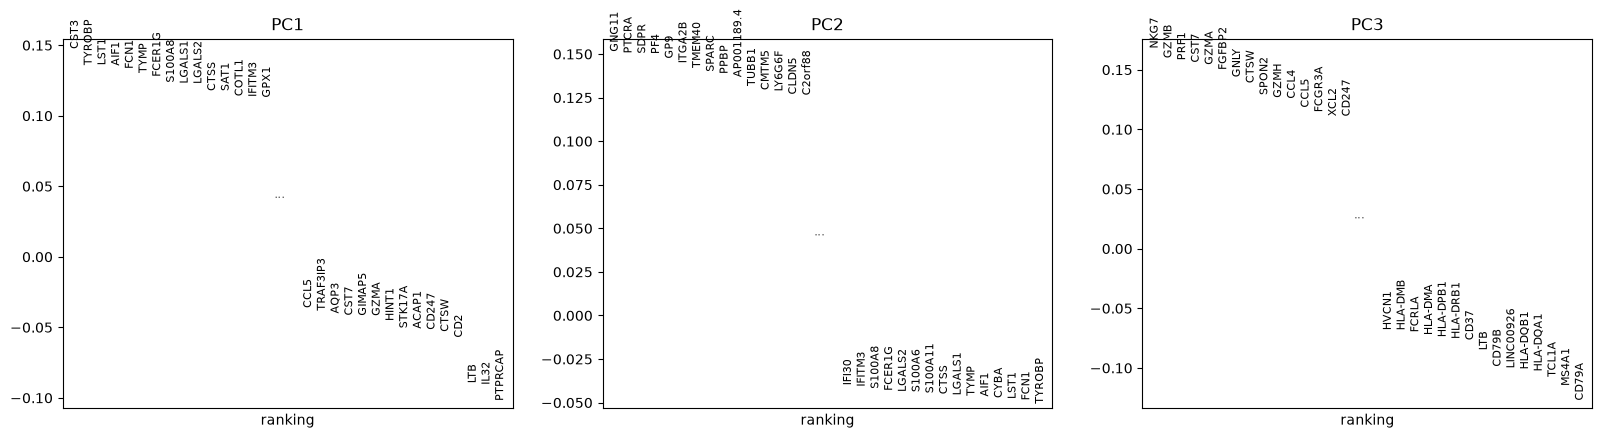

In [5]:
sc.pl.pca_loadings(adata,components="1,2,3",show=False)
plt.savefig("../results/figures/03_pca_loadings.png",dpi=300,bbox_inches="tight")
plt.show()

PCA载荷图。  
正值说明这些基因高表达驱动细胞在PC轴上正向移动，负值说明这些基因高表达驱动细胞在PC轴上负向移动。0附近的值表明没有决定性。

In [6]:
sc.pp.neighbors(adata,n_neighbors=10,n_pcs=40)

A:\pbmc3kP\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


邻域图

In [7]:
print(adata.obsp["distances"].shape,adata.obsp["connectivities"].shape)
conn=adata.obsp["connectivities"]
print(conn[:20,:4].toarray().round(2))

(2643, 2643) (2643, 2643)
[[0.   0.   0.   0.  ]
 [0.   0.   0.   0.  ]
 [0.   0.   0.   0.  ]
 [0.   0.   0.   0.  ]
 [0.   0.   0.   0.  ]
 [0.   0.   0.   0.  ]
 [0.   0.   0.   0.  ]
 [0.   0.   0.   0.  ]
 [0.   0.   0.   0.  ]
 [0.   0.   0.   0.  ]
 [0.   0.46 0.   0.  ]
 [0.   0.   0.   0.  ]
 [0.   0.   0.   0.  ]
 [0.   0.   0.   0.  ]
 [0.   0.   0.   0.  ]
 [0.   0.   0.   0.  ]
 [0.   0.   0.   0.  ]
 [0.   0.   0.   0.  ]
 [0.   0.   0.   0.  ]
 [0.   0.   0.   0.  ]]


在obsp容器中数据的尺寸。  
.shape返回一个元组，表示矩阵的行数和列数
.toarray（）把稀疏矩阵变成稠密矩阵，这样输出的是规整的
.round(2)表示保留两位小数

In [8]:
adata.write("../data/processed/pbmc3k_pca_neighbors.h5ad")

zhe'yi'jie'duan